# 05 — MIMIC-IV-ECG Anomalies, Error Labels Catalog & Waveform Galleries

This notebook summarizes the **15-flag per-study error & data-quality catalog** (`mimic_iv_ecg/quality/error_labels.csv.gz`, generated by `mimic_iv_ecg/quality/generate_error_labels.py`) across **all `800,035` MIMIC-IV-ECG studies**:

- **`0_clean`** (`keep`): Zero warning or error flags.
- **`1_minor_warning`** (`keep_with_cleaning`): Unlinked note, duplicate note link, `<not specified>` filtering, `29999` P-wave sentinel (often `AF`/paced), `pacemaker`, or `pediatric`.
- **`2_moderate_anomaly`** (`review_or_downweight`): Same-timestamp duplicate study, `50 Hz` European notch on Boston US cart, or RR vs bradycardia/tachycardia report contradiction.
- **`3_severe_error`** (`exclude`): Machine-flagged **lead reversal**, **poor data / artifact**, empty reports, core QRS/T `29999` sentinels, `int16`/`uint16` overflows, or impossible derived intervals.

,flag,domain,count,pct_of_800k
1,err_tbl_unlinked_note,1. Table / Hardware,190770,23.845
3,err_hw_filtering_unspecified,1. Table / Hardware,107398,13.424
2,err_tbl_duplicate_subject_timestamp,1. Table / Hardware,4163,0.520
4,err_hw_50hz_notch_in_us,1. Table / Hardware,2717,0.340
0,err_tbl_duplicate_note_link,1. Table / Hardware,7,0.001
6,err_meas_sentinel_29999_pwave,2. Machine Measurements,230752,28.843
7,err_meas_int16_overflow_or_zero,2. Machine Measurements,10355,1.294
5,err_meas_sentinel_29999_core,2. Machine Measurements,2858,0.357
8,err_meas_impossible_intervals,2. Machine Measurements,1319,0.165
10,err_rep_lead_reversal,3. Machine Report,23230,2.904


,severity_tier,recommended_action,count,pct
0,0_clean,keep,421460,52.68
1,1_minor_warning,keep_with_cleaning,333848,41.73
2,2_moderate_anomaly,review_or_downweight,6865,0.86
3,3_severe_error,exclude,37862,4.73


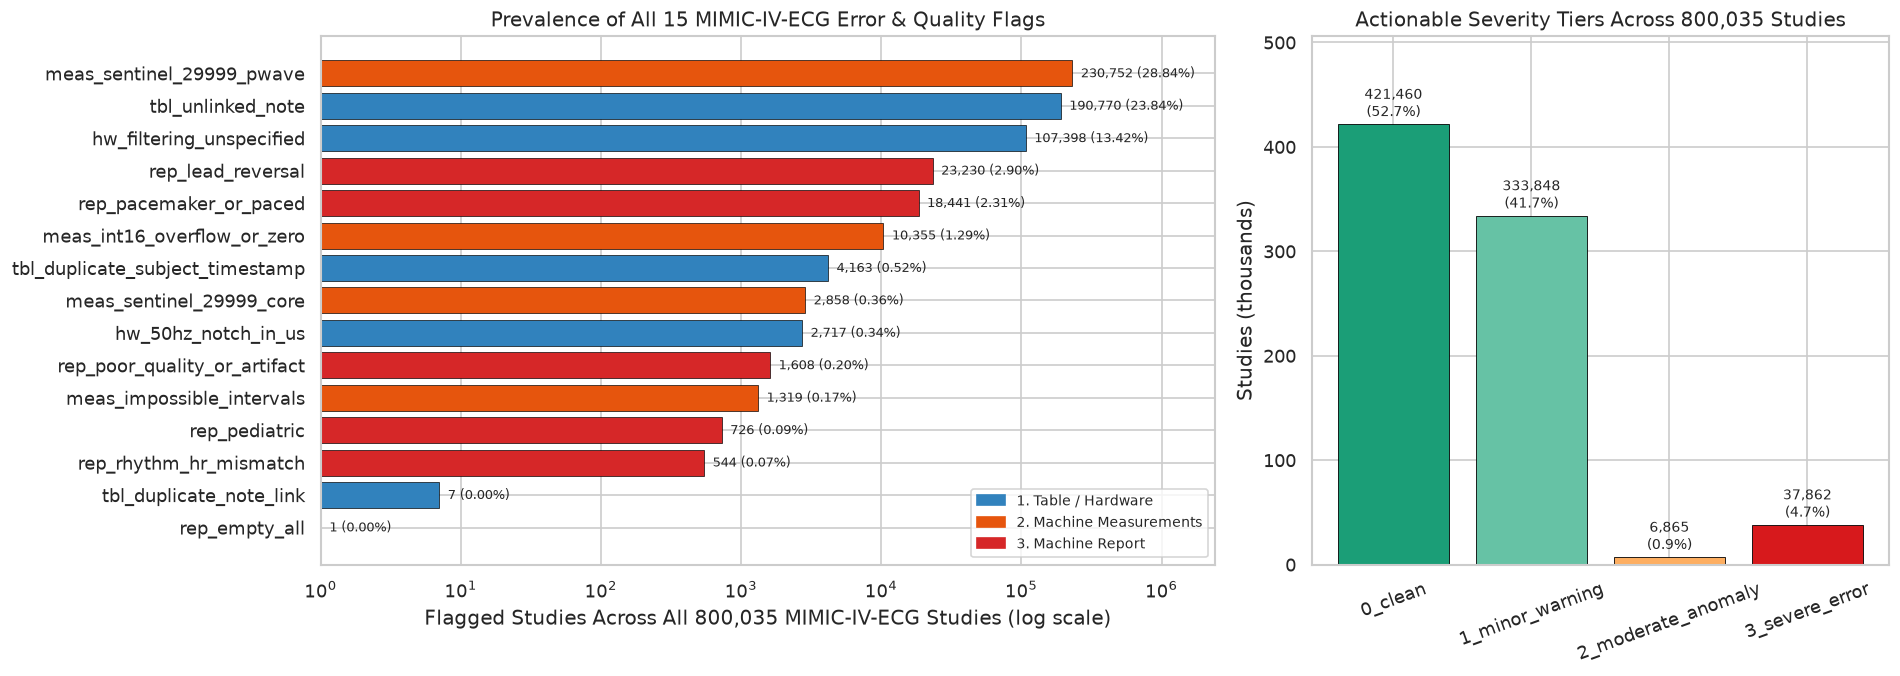

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import wfdb

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _candidate in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_candidate / "mimic_iv_ecg" / "quality" / "error_labels.csv.gz").exists():
        REPO_ROOT = _candidate
        break
else:
    raise FileNotFoundError(f"Could not locate mimic_iv_ecg/quality/error_labels.csv.gz from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from mimic_iv_ecg import MIMICIVECGDataset

MIMIC_DIR = REPO_ROOT / "mimic_iv_ecg"
DATA_DIR = MIMIC_DIR / "data"
QUALITY_DIR = MIMIC_DIR / "quality"
LEADS = MIMICIVECGDataset.LEADS

from matplotlib.patches import Patch

err_df = pd.read_csv(QUALITY_DIR / "error_labels.csv.gz", index_col="study_id")
err_df["error_tags"] = err_df["error_tags"].fillna("")
flag_cols = [c for c in err_df.columns if c.startswith("err_")]

def domain_of(c: str) -> str:
    if c.startswith(("err_tbl_", "err_hw_")):
        return "1. Table / Hardware"
    if c.startswith("err_meas_"):
        return "2. Machine Measurements"
    return "3. Machine Report"

summary = pd.DataFrame([
    {"flag": c, "domain": domain_of(c), "count": int(err_df[c].sum()), "pct_of_800k": round(float(err_df[c].mean() * 100), 3)}
    for c in flag_cols
]).sort_values(["domain", "count"], ascending=[True, False])
display(summary)

tier_summary = err_df.groupby(["severity_tier", "recommended_action"]).size().rename("count").reset_index()
tier_summary["pct"] = (tier_summary["count"] / len(err_df) * 100).round(2)
display(tier_summary)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.8), gridspec_kw={"width_ratios": [1.55, 1]})
plot_tbl = summary.sort_values("count", ascending=True)
dom_pal = {"1. Table / Hardware": "#3182bd", "2. Machine Measurements": "#e6550d", "3. Machine Report": "#d62728"}
axes[0].barh(plot_tbl["flag"].str.replace("^err_", "", regex=True), plot_tbl["count"], color=[dom_pal[d] for d in plot_tbl["domain"]], edgecolor="black", lw=0.4)
axes[0].set_xscale("log")
axes[0].set_xlabel("Flagged Studies Across All 800,035 MIMIC-IV-ECG Studies (log scale)")
axes[0].set_title("Prevalence of All 15 MIMIC-IV-ECG Error & Quality Flags")
for i, (cnt, pct) in enumerate(zip(plot_tbl["count"], plot_tbl["pct_of_800k"])):
    if cnt > 0:
        axes[0].text(cnt * 1.15, i, f"{cnt:,} ({pct:.2f}%)", va="center", fontsize=8)
axes[0].set_xlim(1, len(err_df) * 3.0)
axes[0].legend(handles=[Patch(color=v, label=k) for k, v in dom_pal.items()], loc="lower right", fontsize=8.5)

tier_vc = err_df["severity_tier"].value_counts().sort_index()
axes[1].bar(tier_vc.index, tier_vc.values / 1000.0, color=["#1b9e77", "#66c2a5", "#fdae61", "#d7191c"], edgecolor="black", lw=0.5)
axes[1].set_ylabel("Studies (thousands)")
axes[1].set_title("Actionable Severity Tiers Across 800,035 Studies")
axes[1].tick_params(axis="x", rotation=20)
for i, v in enumerate(tier_vc.values):
    axes[1].text(i, v / 1000.0 + 8, f"{v:,}\n({v/len(err_df)*100:.1f}%)", ha="center", fontsize=8.5)
axes[1].set_ylim(0, tier_vc.max() / 1000.0 * 1.2)

plt.tight_layout()
plt.show()

## 5.1 Real `500 Hz` Waveform Gallery Across MIMIC-IV-ECG Error Flags & `MIMICIVECGDataset` Filtering

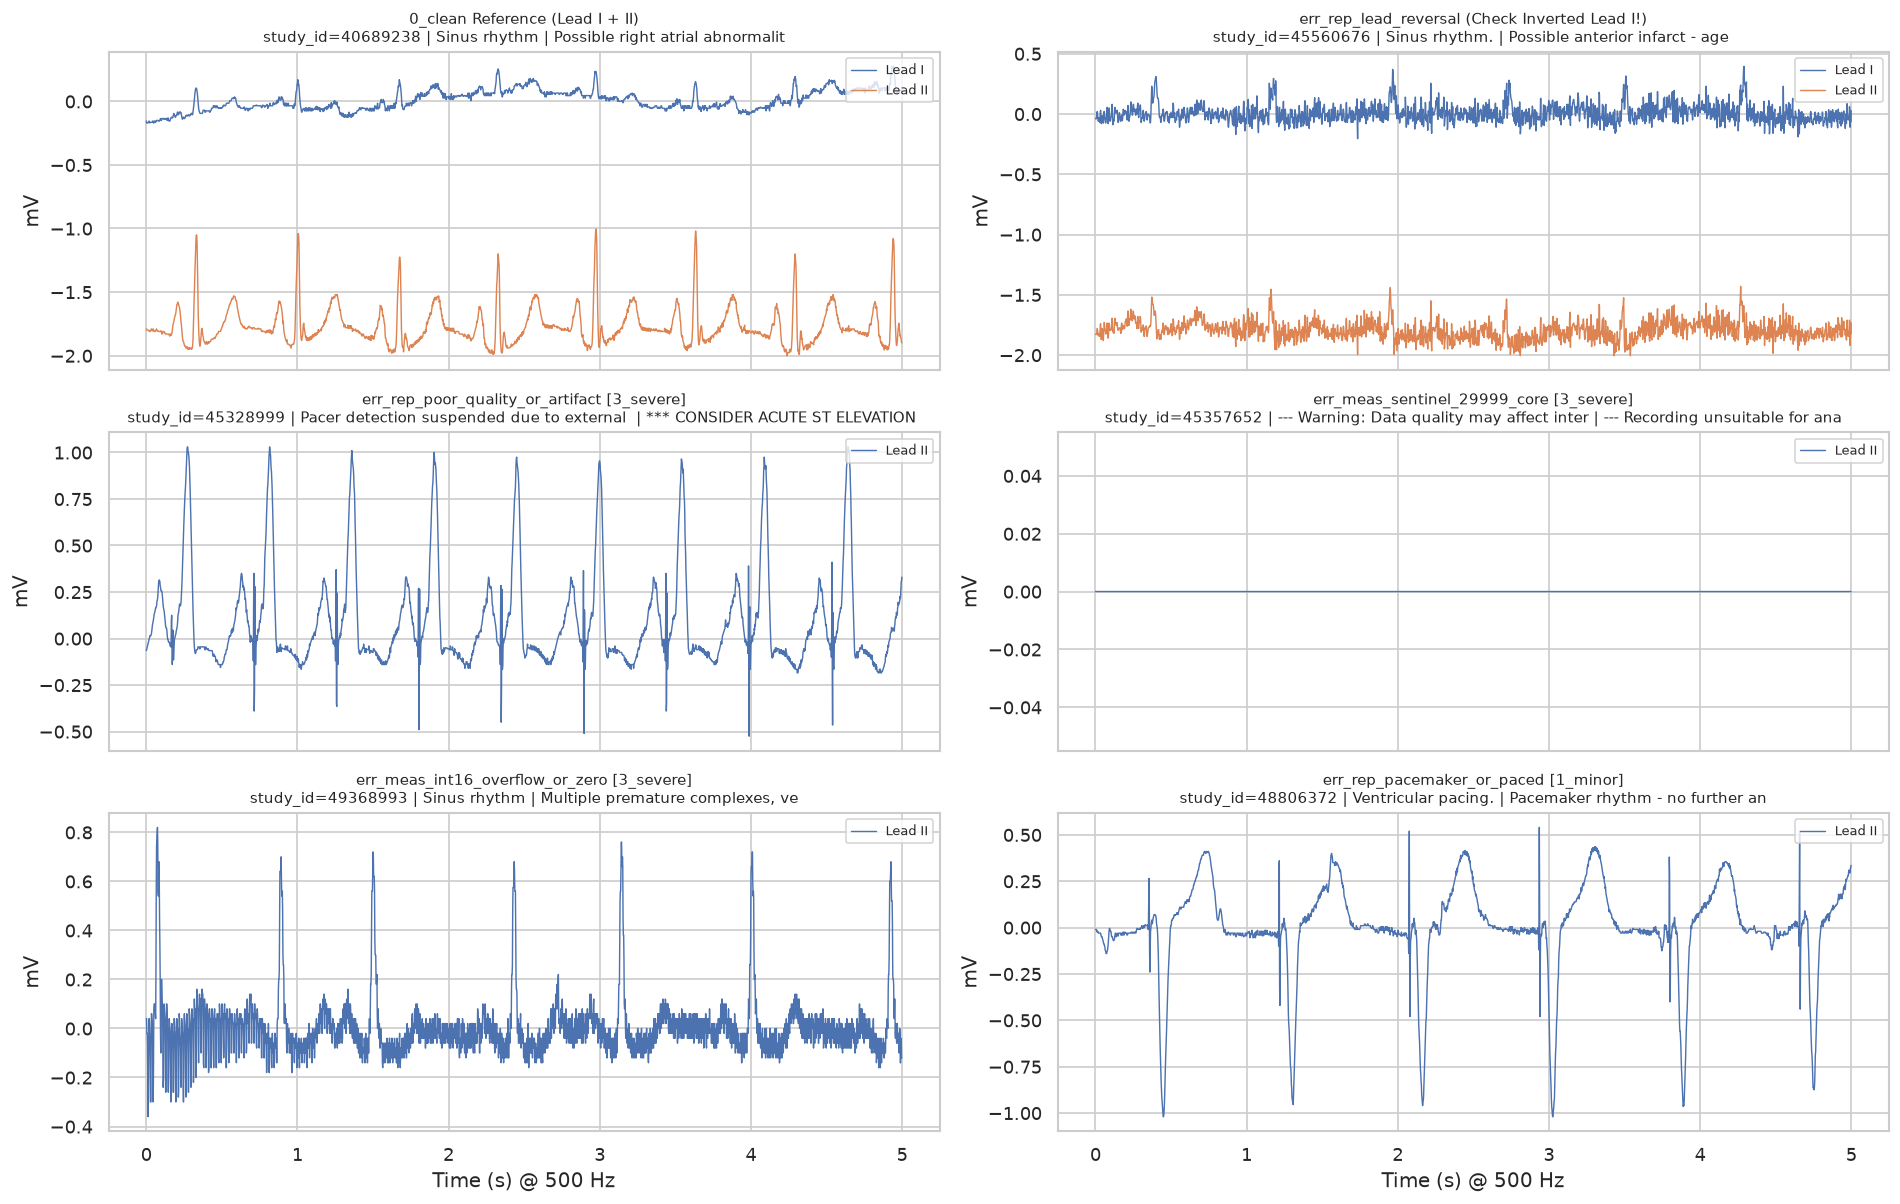

MIMICIVECGDataset.from_subject_split(test, max_error_severity=2) -> 75,700 studies
Sample[0] signal: (12, 5000) | severity: 0_clean | tags: []


In [2]:
rl = pd.read_csv(DATA_DIR / "record_list.csv").set_index("study_id")
mm = pd.read_csv(DATA_DIR / "machine_measurements.csv", usecols=["study_id", "report_0", "report_1", "rr_interval", "qrs_onset", "qrs_end"]).set_index("study_id")

def first_sid(mask: pd.Series) -> int:
    return int(err_df.index[mask][0])

cases = [
    ("0_clean Reference (Lead I + II)", first_sid(err_df["severity_tier"] == "0_clean"), [0, 1]),
    ("err_rep_lead_reversal (Check Inverted Lead I!)", first_sid(err_df["err_rep_lead_reversal"] == 1), [0, 1]),
    ("err_rep_poor_quality_or_artifact [3_severe]", first_sid(err_df["err_rep_poor_quality_or_artifact"] == 1), [1]),
    ("err_meas_sentinel_29999_core [3_severe]", first_sid(err_df["err_meas_sentinel_29999_core"] == 1), [1]),
    ("err_meas_int16_overflow_or_zero [3_severe]", first_sid(err_df["err_meas_int16_overflow_or_zero"] == 1), [1]),
    ("err_rep_pacemaker_or_paced [1_minor]", first_sid(err_df["err_rep_pacemaker_or_paced"] == 1), [1]),
]

fig, axes = plt.subplots(3, 2, figsize=(16, 10.2), sharex=True)
axes = axes.ravel()
T_SHOW = 2500  # 5.0 seconds @ 500 Hz
t = np.arange(T_SHOW) / 500.0

for ax, (title, sid, lead_idxs) in zip(axes, cases):
    sig, _ = wfdb.rdsamp(str(DATA_DIR / rl.loc[sid, "path"]))
    sig = np.nan_to_num(sig)
    for k, li in enumerate(lead_idxs):
        ax.plot(t, np.clip(sig[:T_SHOW, li], -3.0, 3.0) - k * 1.8, lw=0.85, label=f"Lead {LEADS[li]}")
    r0 = str(mm.loc[sid, "report_0"])
    r1 = str(mm.loc[sid, "report_1"])
    ax.set_title(f"{title}\nstudy_id={sid} | {r0[:42]} | {r1[:32]}", fontsize=8.8)
    ax.set_ylabel("mV")
    ax.legend(fontsize=7.5, loc="upper right")

axes[4].set_xlabel("Time (s) @ 500 Hz")
axes[5].set_xlabel("Time (s) @ 500 Hz")
plt.tight_layout()
plt.show()

# Live MIMICIVECGDataset smoke test with subject split + error_labels + clean_sentinels
ds_test = MIMICIVECGDataset.from_subject_split(
    split="test", load_measurements=True, clean_sentinels=True,
    load_error_labels=True, max_error_severity=2,
)
s0 = ds_test[0]
print(f"MIMICIVECGDataset.from_subject_split(test, max_error_severity=2) -> {len(ds_test):,} studies")
print("Sample[0] signal:", s0["signal"].shape, "| severity:", s0["error_labels"]["severity_tier"], "| tags:", s0["error_labels"]["error_tags"])